# Clustering fournisseurs

**Objectif :** regrouper les fournisseurs selon leur performance (qualité, volume, diversité de produits) afin d'identifier des profils types.

**Livrable :** les segments sont exportés vers `parquet_for_powerbi/vendor_segments.parquet` pour alimenter le dashboard Power BI (page Achat).

**Features :** `avg_reject_rate`, `avg_receipt_rate`, `avg_order_qty`, `product_diversity`.

**Filtre :** seuls les fournisseurs ayant au moins **30 lignes d'achat** sont clusterisés (en dessous, les taux sont peu fiables statistiquement). Les fournisseurs exclus sont classés par règle métier en section 5 bis.

**Résultat :** 104 fournisseurs répartis en 5 segments :
- **K-Means (79 fournisseurs)** : Gros volumes (44), Petites séries (22), Généralistes (13)
- **Règles métier (25 fournisseurs)** : Sans commande (18), Peu d'historique (7)

In [57]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

pd.set_option("display.max_columns", None)

## 1. Construction de la table de features par fournisseur

**Source :** base SQLite `adventureworks.db`, tables `PurchaseOrderDetail` (lignes de commande) et `PurchaseOrderHeader` (qui porte le `vendorid`), jointes sur `purchaseorderid`.

**Granularité :** 1 ligne = 1 fournisseur. Les lignes de commande sont agrégées par `vendorid`.

**Indicateurs calculés :**
- `avg_reject_rate` : moyenne de `rejectedqty / orderqty` (qualité)
- `avg_receipt_rate` : moyenne de `receivedqty / orderqty` (livraison complète)
- `avg_order_qty` : quantité moyenne par ligne de commande (volume)
- `product_diversity` : nombre de produits distincts fournis (diversité)
- `total_orders` : nombre de lignes d'achat (sert uniquement au filtre, pas au clustering)

**Filtres :**
- `orderqty > 0` : évite la division par zéro.
- `HAVING COUNT(*) >= 30` : on ne garde que les fournisseurs avec au moins 30 lignes d'achat. En dessous, un taux de rejet de 0 % est un artefact de petit échantillon, pas une preuve de fiabilité. Résultat attendu : 79 fournisseurs. Les autres (7 avec peu d'historique, 18 sans commande) sont traités par règle métier en section 5 bis.

In [58]:
conn = sqlite3.connect("../database/adventureworks.db")

query = """
SELECT
    poh.vendorid,
    COUNT(*) AS total_orders,
    AVG(CAST(pod.rejectedqty AS FLOAT) / pod.orderqty) AS avg_reject_rate,
    AVG(CAST(pod.receivedqty AS FLOAT) / pod.orderqty) AS avg_receipt_rate,
    AVG(pod.orderqty) AS avg_order_qty,
    COUNT(DISTINCT pod.productid) AS product_diversity
FROM purchaseorderdetail pod
LEFT JOIN purchaseorderheader poh
    ON pod.purchaseorderid = poh.purchaseorderid
WHERE pod.orderqty > 0
GROUP BY poh.vendorid
HAVING COUNT(*) >= 30
ORDER BY avg_reject_rate DESC
"""

vendor_df = pd.read_sql(query, conn)
conn.close()

print(vendor_df.shape)
vendor_df.round(2).head()

(79, 6)


,vendorid,total_orders,avg_reject_rate,avg_receipt_rate,avg_order_qty,product_diversity
0,1510,51,0.06,1.00,3.0,1
1,1664,51,0.05,0.98,550.0,1
2,1588,100,0.05,0.99,550.0,2
3,1560,102,0.05,0.99,550.0,2
4,1658,102,0.05,0.99,550.0,2


## 2. Standardisation

Les 4 features n'ont pas la même échelle (`avg_reject_rate` ∈ [0 ; 0,06], `avg_order_qty` jusqu'à plusieurs milliers). K-Means repose sur des distances : sans standardisation, `avg_order_qty` dominerait le clustering. `StandardScaler` ramène chaque variable à une moyenne de 0 et un écart-type de 1.

In [59]:
feature_cols = ["avg_reject_rate", "avg_receipt_rate", "avg_order_qty", "product_diversity"]
X = vendor_df[feature_cols]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pd.DataFrame(X_scaled, columns=feature_cols).describe()

,avg_reject_rate,avg_receipt_rate,avg_order_qty,product_diversity
count,7.900000e+01,7.900000e+01,7.900000e+01,7.900000e+01
mean,-3.372829e-17,7.684430e-15,-1.686415e-17,4.497106e-17
std,1.006390e+00,1.006390e+00,1.006390e+00,1.006390e+00
min,-1.621147e+00,-2.364370e+00,-1.026555e+00,-6.199723e-01
25%,-8.949319e-01,-6.848097e-01,-1.026555e+00,-6.199723e-01
50%,-7.404772e-02,-3.853900e-02,8.858818e-01,-4.701931e-01
75%,5.818880e-01,1.112727e+00,8.858818e-01,-9.574496e-02
max,2.084321e+00,1.112727e+00,3.333242e+00,3.723626e+00


## 3. Choix du nombre de clusters (méthode du coude)

On exécute K-Means pour K de 1 à 9 et on relève l'**inertie** (somme des carrés des distances entre chaque fournisseur et le centre de son cluster). L'inertie diminue toujours quand K augmente : on cherche le « coude », c'est-à-dire le K à partir duquel le gain devient faible.

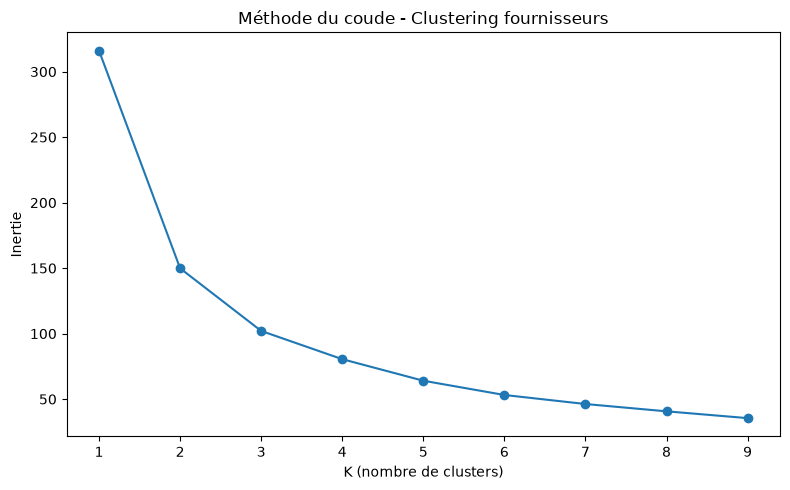

In [60]:
import os
os.makedirs("outputs", exist_ok=True)

inertias = []
k_range = range(1, 10)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_range, inertias, marker="o")
plt.xlabel("K (nombre de clusters)")
plt.ylabel("Inertie")
plt.title("Méthode du coude - Clustering fournisseurs")
plt.tight_layout()
plt.savefig("outputs/elbow_fournisseur.png", bbox_inches="tight")
plt.show()

In [61]:
from sklearn.metrics import silhouette_score

for k in range(2, 7):
    labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_scaled)
    print(f"K={k} : silhouette = {silhouette_score(X_scaled, labels):.3f}")

K=2 : silhouette = 0.471
K=3 : silhouette = 0.473
K=4 : silhouette = 0.386
K=5 : silhouette = 0.429
K=6 : silhouette = 0.416


**Validation par le coefficient de silhouette :** K = 3 obtient le meilleur score (0,473), devant K = 2 (0,471) et nettement devant K = 4 (0,386). On retient **K = 3**. L'écart avec K = 2 est faible ; le choix de K = 3 s'appuie donc aussi sur l'interprétabilité des trois profils obtenus. Un score d'environ 0,47 indique une séparation correcte mais pas parfaite des segments.

## 4. application du K-Means (K = 3)

On ajuste le modèle avec K = 3 sur les 79 fournisseurs standardisés. Chaque fournisseur reçoit un numéro de cluster (0, 1 ou 2), stocké dans la colonne `cluster` de `vendor_df`.

In [62]:
K_CHOISI = 3

kmeans = KMeans(n_clusters=K_CHOISI, random_state=42, n_init=10)
vendor_df["cluster"] = kmeans.fit_predict(X_scaled)

vendor_df["cluster"].value_counts().sort_index()

cluster
0    13
1    44
2    22
Name: count, dtype: int64

In [63]:
cluster_profile = vendor_df.groupby("cluster")[feature_cols].mean().round(3)

## 5. Profil de chaque cluster

Moyenne des 4 features par cluster, en valeurs d'origine (non standardisées), pour interpréter chaque groupe. Les noms des segments (Gros volumes, Petites séries, Généralistes) sont attribués d'après ce tableau, pas d'après le numéro de cluster, qui est arbitraire.

In [70]:
cluster_profile["nb_fournisseurs"] = vendor_df["cluster"].value_counts().sort_index()
cluster_profile = cluster_profile.sort_values("nb_fournisseurs", ascending=False)
cluster_profile

,avg_reject_rate,avg_receipt_rate,avg_order_qty,product_diversity,nb_fournisseurs
cluster,,,,,
1,0.034,0.989,510.227,2.068,44
2,0.019,0.999,18.037,3.182,22
0,0.009,1.000,45.077,18.846,13


**Lecture des profils :**

| Cluster | Nom retenu | Fournisseurs | Rejet moyen | Quantité par ligne | Produits différents |
|---|---|---|---|---|---|
| 1 | **Gros volumes** | 44 | 3,4 % | 510 | 2 |
| 2 | **Petites séries** | 22 | 1,9 % | 18 | 3 |
| 0 | **Généralistes** | 13 | 0,9 % | 45 | 19 |

- **Gros volumes** (44 fournisseurs, le segment le plus nombreux) : peu de références, très grosses quantités par ligne et **taux de rejet le plus élevé**. C'est le segment qui porte le risque qualité.
- **Petites séries** (22) : petites quantités, qualité intermédiaire.
- **Généralistes** (13) : catalogue large et meilleure qualité.

**Limites :**
- Les numéros de cluster sont arbitraires ; les noms viennent de la lecture du tableau ci-dessus.
- La segmentation reflète surtout l'**échelle** et la **diversité** des fournisseurs, plus que leur qualité pure. Exemple : le fournisseur n°1510 (5,9 % de rejet pour une quantité moyenne de 3) se retrouve dans « Petites séries ».
- Les 25 fournisseurs hors K-Means (**Peu d'historique** : 7 ; **Sans commande** : 18) sont classés par règle métier. Ils ne sont **pas évalués** en risque : « Peu d'historique » veut dire données insuffisantes, pas fournisseur sans risque.

## 5 bis. Segmentation complète des 104 fournisseurs

Le K-Means ne porte que sur les 79 fournisseurs ayant au moins 30 lignes d'achat. On complète avec deux segments définis par règle métier :
- **Sans commande** : aucune ligne d'achat (18 fournisseurs) ;
- **Peu d'historique** : moins de 30 lignes, taux de rejet peu fiable (7 fournisseurs).

In [72]:
# Tous les fournisseurs du référentiel, avec leur nombre de lignes d'achat (0 si aucune commande)
conn = sqlite3.connect("../database/adventureworks.db")
all_vendors = pd.read_sql("""
SELECT v.businessentityid AS vendorid,
       v.name,
       COUNT(pod.purchaseorderdetailid) AS nb_lignes
FROM vendor v
LEFT JOIN purchaseorderheader poh ON poh.vendorid = v.businessentityid
LEFT JOIN purchaseorderdetail pod ON pod.purchaseorderid = poh.purchaseorderid
GROUP BY v.businessentityid, v.name
""", conn)
conn.close()

# Noms des clusters (définis en section 5, d'après le tableau de profils de la section 4)
vendor_df["segment"] = vendor_df["cluster"].map(noms_clusters)

# Segment K-Means pour les 79 fournisseurs clusterisés, règle métier pour les 25 autres
all_vendors = all_vendors.merge(vendor_df[["vendorid", "segment"]], on="vendorid", how="left")
all_vendors.loc[all_vendors["nb_lignes"] == 0, "segment"] = "Sans commande"
all_vendors.loc[(all_vendors["nb_lignes"] > 0) & (all_vendors["nb_lignes"] < 30), "segment"] = "Peu d'historique"

print(all_vendors.shape)
all_vendors["segment"].value_counts()

(104, 4)


segment
Gros volumes        44
Petites séries      22
Sans commande       18
Généralistes        13
Peu d'historique     7
Name: count, dtype: int64

## 6. Visualisation (projection PCA)

Les 4 features sont projetées sur 2 axes par une **ACP (PCA)** pour pouvoir afficher les clusters dans un plan. Les deux premiers axes conservent environ **82 %** de l'information (PC1 66,5 % + PC2 15,6 %), ce qui rend la projection fidèle.

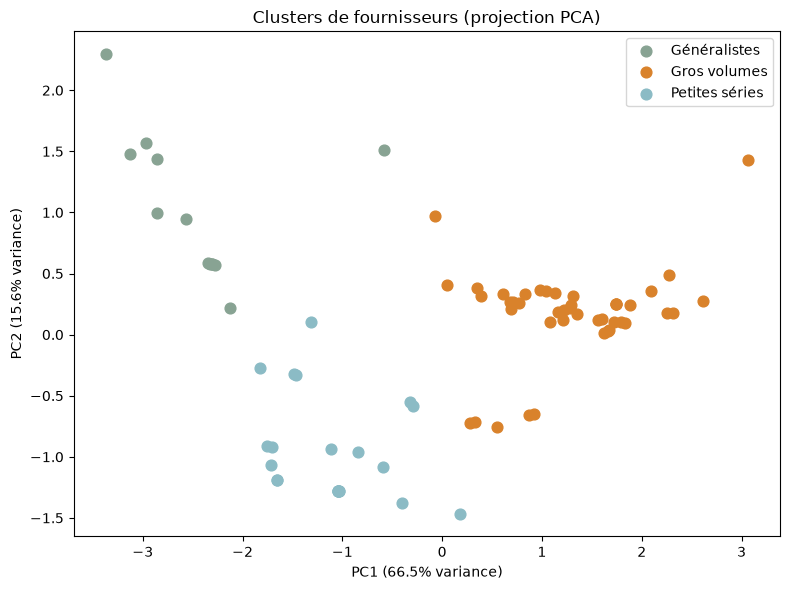

In [93]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
X_pca[:, 0] = -X_pca[:, 0]

noms_clusters = {0: "Généralistes", 1: "Gros volumes", 2: "Petites séries"}

# Mêmes couleurs que dans le dashboard Power BI
couleurs = {
    "Gros volumes": "#D9822B",
    "Petites séries": "#8BBBC5",
    "Généralistes": "#88A393",
}

plt.figure(figsize=(8, 6))
for cl, nom in noms_clusters.items():
    masque = vendor_df["cluster"] == cl
    plt.scatter(X_pca[masque, 0], X_pca[masque, 1],
                label=nom, color=couleurs[nom], s=60)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
plt.title("Clusters de fournisseurs (projection PCA)")
plt.legend()
plt.tight_layout()
plt.savefig("outputs/clusters_pca.png", bbox_inches="tight")
plt.show()

In [76]:
loadings = pd.DataFrame(pca.components_.T, index=feature_cols, columns=["PC1", "PC2"]).round(2)
loadings

,PC1,PC2
avg_reject_rate,-0.49,-0.07
avg_receipt_rate,0.54,-0.23
avg_order_qty,-0.51,0.53
product_diversity,0.45,0.81


## 7. Export des résultats

- `outputs/vendor_clusters.csv` : les 79 fournisseurs clusterisés, avec leurs features (trace de l'analyse).
- `parquet_for_powerbi/vendor_segments.parquet` : les 104 fournisseurs et leur segment, chargés dans Power BI (relation 1-1 avec la table Vendor).

In [67]:
vendor_df.to_csv("outputs/vendor_clusters.csv", index=False, sep=";")
vendor_df.head(20)

,vendorid,total_orders,avg_reject_rate,avg_receipt_rate,avg_order_qty,product_diversity,cluster,segment
0,1510,51,0.058824,1.000000,3.0,1,2,Petites séries
1,1664,51,0.053832,0.982460,550.0,1,1,Gros volumes
2,1588,100,0.053455,0.990091,550.0,2,1,Gros volumes
3,1560,102,0.052888,0.992228,550.0,2,1,Gros volumes
4,1658,102,0.052888,0.991747,550.0,2,1,Gros volumes
5,1586,100,0.052455,0.991582,550.0,2,1,Gros volumes
6,1576,100,0.051964,0.990091,550.0,2,1,Gros volumes
7,1682,50,0.051927,0.985091,550.0,1,1,Gros volumes
8,1590,100,0.050984,0.989544,1250.0,2,1,Gros volumes
9,1620,51,0.050909,0.985383,550.0,1,1,Gros volumes


In [74]:
# Export de la segmentation complète pour Power BI, au même endroit que les autres tables
chemin = "../parquet_for_powerbi/vendor_segments.parquet"
all_vendors.to_parquet(chemin, index=False)

# Vérification : on relit le fichier exporté
verif = pd.read_parquet(chemin)
print(f"Fichier exporté : {chemin}")
print(f"{verif.shape[0]} fournisseurs, {verif.shape[1]} colonnes : {list(verif.columns)}")
verif["segment"].value_counts()

Fichier exporté : ../parquet_for_powerbi/vendor_segments.parquet
104 fournisseurs, 4 colonnes : ['vendorid', 'name', 'nb_lignes', 'segment']


segment
Gros volumes        44
Petites séries      22
Sans commande       18
Généralistes        13
Peu d'historique     7
Name: count, dtype: int64

## 8. Conclusion

- **Segmentation hybride** : K-Means pour les fournisseurs ayant assez d'historique, règles métier pour les autres. Aucun fournisseur du référentiel n'est laissé de côté.
- **Résultat principal** : le segment **« Gros volumes »** (44 fournisseurs) concentre les plus gros montants d'achat **et** le taux de rejet le plus élevé (3,4 %). Le risque qualité se situe chez les fournisseurs les plus stratégiques.
- **Usage métier** : prioriser un plan qualité sur ce segment, en commençant par les fournisseurs du top 10.

**Limites :**
- 79 fournisseurs seulement : la segmentation est indicative, pas un modèle de production.
- K-Means suppose des groupes de forme sphérique ; `avg_order_qty` très dispersée influence fortement les clusters, malgré la standardisation.
- Les taux sont calculés sur les lignes d'achat, sans pondération par le montant.